In [1]:
import json
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

import corpora
from evaluation import competitors
from evaluation import scoring as report
from schemaoracle import cache, inventory

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

# Section 4 is GDC-SM, pooled over its 569 source columns. Pooling weights each
# column equally and each study by its size; the per-study mean is the Appendix.
CORPUS = "gdc"
RETRIEVER = "qwen"
ORDERS = ["qwen", "magneto"]          # section 4.5 compares the two, paired
ARMS = ["rerank", "gated", "paged"]
PRUNE = ""                            # no filter anywhere in this section
TOP_K, WINDOW, TAU = 20, 20, 0.0
VARIANTS = ["tgt-match-retriever"]

MODELS = {
    "claude-sonnet-5": ("Sonnet 5", "#0f766e"),
    "deepseek-v4.1-flash-cloud": ("DeepSeek V4.1 Flash", "#56b4e9"),
    # The decision backend is gone, so no new Jev run can be made. Its
    # 13,441 runs are still on disk and still scoreable: uncomment to
    # bring its rows back.
    #"jev-1.13": ("Jev 1.13", "#cc79a7"),
    #"deepseek-v4-flash-cloud": ("DeepSeek V4 Flash", "#2563eb"),
    #"deepseek-v4-pro-cloud": ("DeepSeek V4 Pro", "#d55e00"),
}
COMPETITORS = {
    "coma": "COMA",
    "coma-instances": "COMA, instances",
    "jaccard-levenshtein": "Jaccard-Levenshtein",
    competitors.magneto_llm_tag(RETRIEVER, "deepseek/deepseek-v4.1-flash"):
        "Magneto + LLM",
}

RUNS = REPO / "results" / "runs"
COMPETITOR_RUNS = REPO / "results" / "competitors"
FIGDIR = REPO / "figures"
TABDIR = REPO / "results"

C_INK, C_MUTE = "#1e293b", "#94a3b8"
mpl.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 400, "savefig.bbox": "tight",
    "font.family": "serif", "font.serif": ["DejaVu Serif"], "font.size": 7.5,
    "text.color": C_INK, "xtick.color": C_INK, "ytick.color": C_INK,
    "axes.edgecolor": C_INK, "axes.labelcolor": C_INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.16, "grid.linewidth": 0.4,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

PAIRS = corpora.load(CORPUS)
NAMES = [cache.fs_safe(p["name"]) for p in PAIRS]
N_SRC = sum(p["source_df"].shape[1] for p in PAIRS)


def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIGDIR / f"{name}.{ext}")
    print(f"wrote figures/{name}.pdf and .png")


print(f"{CORPUS}: {len(PAIRS)} studies, {N_SRC} source columns")


gdc: 10 studies, 569 source columns


In [2]:
# --- Table 1: the corpora -------------------------------------------------
rows = []
for name in ["gdc", "valentine/opendata", "valentine/chembl",
             "valentine/tpc-di", "valentine/magellan", "valentine/wikidata"]:
    pairs = corpora.load(name)
    src = sum(p["source_df"].shape[1] for p in pairs)
    gold_cols = sum(len({s for s, _ in p["ground_truth"]}) for p in pairs)
    rows.append({"corpus": name, "studies": len(pairs), "source columns": src,
                 "target columns": sum(p["target_df"].shape[1] for p in pairs),
                 "gold pairs": sum(len(p["ground_truth"]) for p in pairs),
                 "columns with gold": gold_cols,
                 "no gold": src - gold_cols,
                 "share no gold": round((src - gold_cols) / src, 3)})
CORPORA = pd.DataFrame(rows)
CORPORA.to_csv(TABDIR / "table1_corpora.csv", index=False)
display(CORPORA)


C:\Users\muril\SchemaOracle\corpora\registry.py:129: UserWarning: valentine/wikidata: ground truth names 2 source column(s) that are not in the source frame (Wikidata/Musicians/Musicians_unionable: givenName; Wikidata/Musicians/Musicians_viewunion: givenName). No matcher can reach them, and they are counted by MRR but not by the precision, so the two use different denominators.
  _warn_unreachable_gold(name, out)


,corpus,studies,source columns,target columns,gold pairs,columns with gold,no gold,share no gold
0,gdc,10,569,7360,259,165,404,0.710
1,valentine/opendata,179,6825,6825,4521,4521,2304,0.338
2,valentine/chembl,180,3060,3132,2052,2052,1008,0.329
3,valentine/tpc-di,176,2842,2949,1919,1919,923,0.325
4,valentine/magellan,7,41,41,41,41,0,0.000
5,valentine/wikidata,4,60,60,40,40,20,0.333


In [3]:
# --- the design, and Table 2 ----------------------------------------------
# One row per (order, arm, model), pooled. A cell enters only if it holds every
# study and every column under one variant: a model short on one arm is not a
# measurement of the same thing as the others.
def tagged(frame):
    return frame.assign(model=frame["arm"].str.split("__").str[0],
                        variant=frame["arm"].str.split("__").str[1:].str.join("__"))


inv = tagged(inventory.scan(RUNS, corpus=CORPUS, pairs=NAMES, kinds=tuple(ARMS)))
inv = inv[(inv["rep"] == 1) & (inv["prune"] == PRUNE)
          & inv["retriever"].isin(ORDERS) & inv["model"].isin(MODELS)
          & inv["variant"].isin(VARIANTS)
          & ((inv["kind"] != "paged") & (inv["top_k"] == TOP_K)
             | (inv["kind"] == "paged") & (inv["window"] == WINDOW)
             & (inv["threshold"] == TAU))]
OK = tagged(inventory.check(inv, verbose=False, max_fallback=1.0))

# The fallback gate, pooled. `inventory.check` applies it per run, and on a
# 28-column study one reply that trailed off is 3.6%, above the 2% separator
# with nothing in between: a per-run rate has no resolution below 1/n. The
# pooled cell is what enters the table, so that is where the share is judged.
MAX_FB = inventory.MAX_FALLBACK


def retriever_share(runs):
    """How much of a cell the retriever answered instead of the model."""
    n = runs["n_columns"].sum()
    return (runs["n_fallback"].sum() / n) if n else 0.0


RUNS_OF, rows, missing = {}, [], []
for ret in ORDERS:
    for arm in ARMS:
        for m in MODELS:
            runs = OK[(OK["retriever"] == ret) & (OK["kind"] == arm)
                      & (OK["model"] == m)]
            if set(runs["pair"]) != set(NAMES) or runs["n_columns"].sum() != N_SRC:
                missing.append({"order": ret, "arm": arm, "model": m,
                                "studies": len(set(runs["pair"])),
                                "columns": int(runs["n_columns"].sum())})
                continue
            share = retriever_share(runs)
            if share > MAX_FB:
                print(f"excluded: {ret} / {arm} / {m}: the retriever "
                      f"answered {share:.1%} of the columns, over {MAX_FB:.0%}")
                continue
            RUNS_OF[ret, arm, m] = runs
            s = report.score(runs, PAIRS, results=RUNS, corpus=CORPUS,
                             kind=arm).iloc[0]
            # The labels come last: `score` returns its own `arm` (the model
            # tag) and `model` (provider-qualified), and spreading it first
            # would overwrite the protocol and the display name with those.
            rows.append({**s, "order": ret, "arm": arm,
                         "model": MODELS[m][0], "model_key": m})

SCORED = pd.DataFrame(rows)
for r in missing:
    print(f"not whole: {r['order']} / {r['arm']} / {r['model']}: "
          f"{r['studies']} of {len(NAMES)} studies, {r['columns']:,} of {N_SRC}")

SHOW = ["arm", "model", "mrr", "mrr_abstain", "recall@1", "recall@20",
        "top1", "precision_committed", "precision_evaluated",
        "f1_committed", "f1_evaluated", "calls_per_column"]
TABLE2 = SCORED[SCORED["order"] == RETRIEVER][SHOW].round(3)
TABLE2.to_csv(TABDIR / "table2_arms.csv", index=False)
display(TABLE2)


not whole: magneto / gated / deepseek-v4.1-flash-cloud: 9 of 10 studies, 390 of 569


,arm,model,mrr,mrr_abstain,recall@1,recall@20,top1,precision_committed,precision_evaluated,f1_committed,f1_evaluated,calls_per_column
0,rerank,Sonnet 5,0.913,0.265,0.568,0.923,0.891,0.258,0.258,0.401,0.401,1.00
1,rerank,DeepSeek V4.1 Flash,0.896,0.260,0.552,0.927,0.867,0.251,0.251,0.390,0.390,1.00
2,gated,Sonnet 5,0.915,0.524,0.568,0.907,0.891,0.351,0.258,0.503,0.401,1.00
3,gated,DeepSeek V4.1 Flash,0.896,0.409,0.552,0.927,0.867,0.297,0.251,0.442,0.390,1.00
4,paged,Sonnet 5,0.924,0.393,0.575,0.919,0.903,0.299,0.262,0.449,0.406,6.07
5,paged,DeepSeek V4.1 Flash,0.908,0.393,0.556,0.938,0.873,0.291,0.253,0.436,0.392,6.04


In [4]:
# --- the retrieval ceiling, and the ranges the text quotes ----------------
order, gt = report.retrieval_rankings(PAIRS, results=RUNS, corpus=CORPUS,
                                      retriever=RETRIEVER, covered=NAMES)
RET = report.metrics(order, gt, {c: True for c in order})
N_GOLD = RET["n_gold_columns"]
N_FREE = N_SRC - N_GOLD

print(f"retrieval order, {RETRIEVER}")
for k in ("mrr", "recall@1", "recall@20"):
    print(f"  {k:10s} {RET[k]:.3f}")
print(f"  beyond rank {TOP_K}: {1 - RET[f'recall@{TOP_K}']:.3f} of gold pairs")
print("")
print(f"{N_GOLD} of {N_SRC} columns carry gold, {N_FREE} carry none; "
      f"a matcher that never declines scores at most {N_GOLD / N_SRC:.3f} "
      "on MRR with absence")

Q = SCORED[SCORED["order"] == RETRIEVER]
for label, col in [("MRR", "mrr"), ("MRR with absence", "mrr_abstain"),
                   ("F1 evaluated", "f1_evaluated"),
                   ("F1 committed", "f1_committed")]:
    print(f"  {label:18s} {Q[col].min():.3f} to {Q[col].max():.3f}")


retrieval order, qwen
  mrr        0.812
  recall@1   0.456
  recall@20  0.927
  beyond rank 20: 0.073 of gold pairs

165 of 569 columns carry gold, 404 carry none; a matcher that never declines scores at most 0.290 on MRR with absence
  MRR                0.896 to 0.924
  MRR with absence   0.260 to 0.524
  F1 evaluated       0.390 to 0.406
  F1 committed       0.390 to 0.503


wrote figures/fig3_mrr_two_ways.pdf and .png


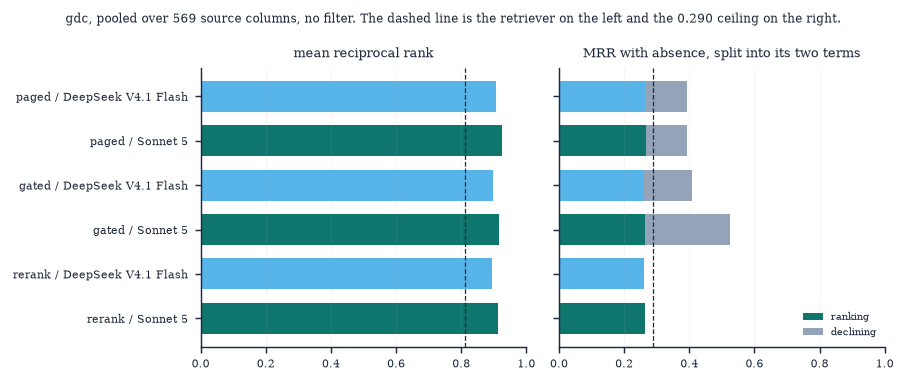

In [5]:
# --- Figure 3: the same runs, two ways ------------------------------------
# The right panel is stacked into the two terms of the decomposition: ranking on
# the columns that have gold, and declining on the columns that do not.
Q = SCORED[SCORED["order"] == RETRIEVER].reset_index(drop=True)
w_gold, w_free = N_GOLD / N_SRC, N_FREE / N_SRC

fig, axes = plt.subplots(1, 2, figsize=(7.0, 0.32 * len(Q) + 1.0), sharey=True)
y = np.arange(len(Q))
lab = [f"{r['arm']} / {r['model']}" for _, r in Q.iterrows()]

axes[0].barh(y, Q["mrr"], height=0.7,
             color=[MODELS[k][1] for k in Q["model_key"]])
axes[0].set_title("mean reciprocal rank", fontsize=7)
axes[0].axvline(RET["mrr"], color=C_INK, lw=0.7, ls="--")

rank = w_gold * Q["mrr"]
axes[1].barh(y, rank, height=0.7,
             color=[MODELS[k][1] for k in Q["model_key"]], label="ranking")
axes[1].barh(y, w_free * Q["abstain_recall"], height=0.7, left=rank,
             color=C_MUTE, label="declining")
axes[1].axvline(w_gold, color=C_INK, lw=0.7, ls="--")
axes[1].set_title(r"MRR with absence, split into its two terms", fontsize=7)
axes[1].legend(fontsize=5.5, frameon=False, loc="lower right")

for ax in axes:
    ax.set_xlim(0, 1.0)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="x", labelsize=6)
axes[0].set_yticks(y, lab, fontsize=6)
fig.suptitle(f"{CORPUS}, pooled over {N_SRC} source columns, no filter. "
             f"The dashed line is the retriever on the left and the "
             f"{w_gold:.3f} ceiling on the right.", fontsize=6.5)
fig.tight_layout()
save(fig, "fig3_mrr_two_ways")
plt.show()


wrote figures/fig4_abstention.pdf and .png


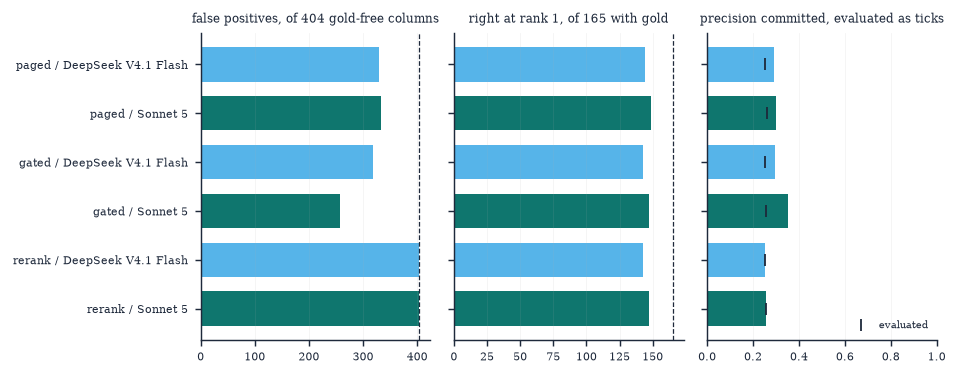

,arm,model,n_declined,n_model_declined,fn_abstained,abstain_precision,abstain_recall,calls_per_column,tokens_in_per_column
0,rerank,Sonnet 5,0,0,0,NaN,0.000,1.00,1367.293
1,rerank,DeepSeek V4.1 Flash,0,0,0,NaN,0.000,1.00,967.272
2,gated,Sonnet 5,150,150,3,0.980,0.364,1.00,1596.293
3,gated,DeepSeek V4.1 Flash,87,87,2,0.977,0.210,1.00,1129.272
4,paged,Sonnet 5,71,71,0,1.000,0.176,6.07,9549.564
5,paged,DeepSeek V4.1 Flash,74,74,0,1.000,0.183,6.04,6726.605


In [6]:
# --- Figure 4: what declining does ----------------------------------------
Q = SCORED[SCORED["order"] == RETRIEVER].reset_index(drop=True)
y = np.arange(len(Q))
lab = [f"{r['arm']} / {r['model']}" for _, r in Q.iterrows()]
col = [MODELS[k][1] for k in Q["model_key"]]

fig, axes = plt.subplots(1, 3, figsize=(7.4, 0.32 * len(Q) + 1.0), sharey=True)

axes[0].barh(y, Q["fp_invented"], height=0.7, color=col)
axes[0].axvline(N_FREE, color=C_INK, lw=0.7, ls="--")
axes[0].set_title(f"false positives, of {N_FREE} gold-free columns", fontsize=6.8)

axes[1].barh(y, Q["tp"], height=0.7, color=col)
axes[1].axvline(N_GOLD, color=C_INK, lw=0.7, ls="--")
axes[1].set_title(f"right at rank 1, of {N_GOLD} with gold", fontsize=6.8)

axes[2].barh(y, Q["precision_committed"], height=0.7, color=col)
axes[2].plot(Q["precision_evaluated"], y, "|", ms=7, color=C_INK,
             label="evaluated")
axes[2].set_xlim(0, 1.0)
axes[2].legend(fontsize=5.5, frameon=False, loc="lower right")
axes[2].set_title("precision committed, evaluated as ticks", fontsize=6.8)

for ax in axes:
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="x", labelsize=6)
axes[0].set_yticks(y, lab, fontsize=6)
fig.tight_layout()
save(fig, "fig4_abstention")
plt.show()

COST = Q[["arm", "model", "n_declined", "n_model_declined", "fn_abstained",
          "abstain_precision", "abstain_recall", "calls_per_column",
          "tokens_in_per_column"]].round(3)
display(COST)


In [7]:
# --- Section 4.4: does paging pay, and does its first block match gated? ---
# The bound: paging can only recover the gold-bearing columns gated declined,
# so it cannot gain more than FN_gated / |S| in MRR with absence.
rows = []
for m in MODELS:
    g = SCORED[(SCORED["order"] == RETRIEVER) & (SCORED["arm"] == "gated")
               & (SCORED["model_key"] == m)]
    p = SCORED[(SCORED["order"] == RETRIEVER) & (SCORED["arm"] == "paged")
               & (SCORED["model_key"] == m)]
    if not len(g) or not len(p):
        continue
    fn = int(g.iloc[0]["fn_abstained"])
    rows.append({"model": MODELS[m][0], "gated": g.iloc[0]["mrr_abstain"],
                 "paged": p.iloc[0]["mrr_abstain"],
                 "FN gated": fn, "bound": g.iloc[0]["mrr_abstain"] + fn / N_SRC,
                 "within bound": p.iloc[0]["mrr_abstain"]
                 <= g.iloc[0]["mrr_abstain"] + fn / N_SRC + 1e-9,
                 "calls/col gated": g.iloc[0]["calls_per_column"],
                 "calls/col paged": p.iloc[0]["calls_per_column"]})
BOUND = pd.DataFrame(rows).round(3)
display(BOUND)


def first_block(runs):
    """Per column, whether the run committed to its first block."""
    out = {}
    for r in runs.itertuples():
        for c in inventory.load(r)["trace"]["columns"]:
            b = (c.get("blocks") or [None])[0]
            if b is not None:
                out[report.namespaced(r.pair, c["source_column"])] = \
                    b.get("verdict") == "accept"
    return out


rows = []
for m in MODELS:
    if (RETRIEVER, "gated", m) not in RUNS_OF or (RETRIEVER, "paged", m) not in RUNS_OF:
        continue
    a = first_block(RUNS_OF[RETRIEVER, "gated", m])
    b = first_block(RUNS_OF[RETRIEVER, "paged", m])
    both = set(a) & set(b)
    same = sum(a[k] == b[k] for k in both)
    rows.append({"model": MODELS[m][0], "columns": len(both),
                 "same first decision": same,
                 "agreement": round(same / len(both), 3) if both else float("nan")})
AGREE = pd.DataFrame(rows)
print("")
print("the bound assumes paged decides its first block as gated does:")
display(AGREE)


,model,gated,paged,FN gated,bound,within bound,calls/col gated,calls/col paged
0,Sonnet 5,0.524,0.393,3,0.529,True,1.0,6.07
1,DeepSeek V4.1 Flash,0.409,0.393,2,0.413,True,1.0,6.04



the bound assumes paged decides its first block as gated does:


,model,columns,same first decision,agreement
0,Sonnet 5,569,499,0.877
1,DeepSeek V4.1 Flash,569,500,0.879


In [8]:
# --- Section 4.4: the tail ------------------------------------------------
# What paging buys and what it costs, per gold pair: recovered beyond the first
# block, against pairs inside it that paged no longer gets right.
order, gt = report.retrieval_rankings(PAIRS, results=RUNS, corpus=CORPUS,
                                      retriever=RETRIEVER, covered=NAMES)
depth = {}
for col, ranked in order.items():
    names = [t for t, _ in ranked]
    for s, t in gt:
        if s == col and t in names:
            depth.setdefault(col, {})[t] = names.index(t) + 1


def hits(runs):
    out = {}
    for r in runs.itertuples():
        for c in inventory.load(r)["trace"]["columns"]:
            key = report.namespaced(r.pair, c["source_column"])
            out[key] = {t for t, _ in (c.get("ranking") or [])}
    return out


rows = []
for m in MODELS:
    if (RETRIEVER, "gated", m) not in RUNS_OF or (RETRIEVER, "paged", m) not in RUNS_OF:
        continue
    g, p = hits(RUNS_OF[RETRIEVER, "gated", m]), hits(RUNS_OF[RETRIEVER, "paged", m])
    deep_won = shallow_lost = 0
    for col, targets in depth.items():
        for t, d in targets.items():
            in_g, in_p = t in g.get(col, ()), t in p.get(col, ())
            if d > TOP_K and in_p and not in_g:
                deep_won += 1
            elif d <= TOP_K and in_g and not in_p:
                shallow_lost += 1
    rows.append({"model": MODELS[m][0],
                 f"gold beyond rank {TOP_K}": sum(
                     1 for c in depth.values() for d in c.values() if d > TOP_K),
                 "recovered by paging": deep_won,
                 f"lost inside rank {TOP_K}": shallow_lost,
                 "net": deep_won - shallow_lost})
TAIL = pd.DataFrame(rows)
display(TAIL)


,model,gold beyond rank 20,recovered by paging,lost inside rank 20,net
0,Sonnet 5,19,2,2,0
1,DeepSeek V4.1 Flash,19,3,0,3


In [9]:
# --- Published matchers, pooled the same way ------------------------------
COMP = report.score_competitors(PAIRS, list(COMPETITORS), results=COMPETITOR_RUNS,
                                corpus=CORPUS, retriever=RETRIEVER)
if len(COMP):
    COMP["matcher"] = COMP["matcher"].map(COMPETITORS).fillna(COMP["matcher"])
    cols = [c for c in ["matcher", "n_studies", "n_columns", "mrr",
                        "mrr_abstain", "recall@1", "recall@20", "top1",
                        "precision_committed", "precision_evaluated",
                        "f1_committed", "f1_evaluated"] if c in COMP.columns]
    short = COMP[COMP["n_columns"] != N_SRC]
    for r in short.itertuples():
        print(f"not whole: {r.matcher}: {r.n_columns:,} of {N_SRC} columns")
    display(COMP[cols].round(3))
    COMP.to_csv(TABDIR / "table2_competitors.csv", index=False)
else:
    print("no competitor runs on this corpus")


,matcher,n_studies,n_columns,mrr,mrr_abstain,recall@1,recall@20,top1,precision_committed,precision_evaluated,f1_committed,f1_evaluated
0,COMA,10,569,0.521,0.360,0.309,0.402,0.485,0.181,0.141,0.264,0.218
1,"COMA, instances",10,569,0.627,0.372,0.378,0.517,0.594,0.218,0.172,0.319,0.267
2,Jaccard-Levenshtein,10,569,0.304,0.382,0.166,0.363,0.261,0.116,0.076,0.161,0.117
3,Magneto + LLM,10,569,0.903,0.264,0.564,0.919,0.885,0.258,0.257,0.399,0.398


In [10]:
# --- Section 4.5: the second order, paired --------------------------------
# Never pooled across orders: one ceiling row cannot describe both. The same
# (arm, model) cell under each, and the lift each protocol adds over its own
# retriever.
rows = []
for ret in ORDERS:
    o, g = report.retrieval_rankings(PAIRS, results=RUNS, corpus=CORPUS,
                                     retriever=ret, covered=NAMES)
    base = report.metrics(o, g, {c: True for c in o})
    for arm in ARMS:
        for m in MODELS:
            cell = SCORED[(SCORED["order"] == ret) & (SCORED["arm"] == arm)
                          & (SCORED["model_key"] == m)]
            if not len(cell):
                continue
            s = cell.iloc[0]
            rows.append({"order": ret, "arm": arm, "model": MODELS[m][0],
                         "ret R@20": base["recall@20"], "ret MRR": base["mrr"],
                         "mrr": s["mrr"], "lift over its retriever":
                         s["mrr"] - base["mrr"],
                         "mrr_abstain": s["mrr_abstain"],
                         "f1_committed": s["f1_committed"]})
ORDERS_TBL = pd.DataFrame(rows).round(3)
display(ORDERS_TBL)
ORDERS_TBL.to_csv(TABDIR / "table_orders.csv", index=False)

missing_ord = [o for o in ORDERS
               if not len(ORDERS_TBL[ORDERS_TBL["order"] == o])]
if missing_ord:
    print(f"no whole cell on: {missing_ord}. Section 4.5 needs both orders.")


,order,arm,model,ret R@20,ret MRR,mrr,lift over its retriever,mrr_abstain,f1_committed
0,qwen,rerank,Sonnet 5,0.927,0.812,0.913,0.101,0.265,0.401
1,qwen,rerank,DeepSeek V4.1 Flash,0.927,0.812,0.896,0.084,0.260,0.390
2,qwen,gated,Sonnet 5,0.927,0.812,0.915,0.103,0.524,0.503
3,qwen,gated,DeepSeek V4.1 Flash,0.927,0.812,0.896,0.085,0.409,0.442
4,qwen,paged,Sonnet 5,0.927,0.812,0.924,0.112,0.393,0.449
5,qwen,paged,DeepSeek V4.1 Flash,0.927,0.812,0.908,0.096,0.393,0.436
6,magneto,rerank,Sonnet 5,0.772,0.702,0.857,0.155,0.249,0.379
7,magneto,rerank,DeepSeek V4.1 Flash,0.772,0.702,0.800,0.098,0.232,0.343
8,magneto,gated,Sonnet 5,0.772,0.702,0.848,0.146,0.636,0.544
9,magneto,paged,Sonnet 5,0.772,0.702,0.891,0.189,0.389,0.439


In [11]:
# --- The noise floor ------------------------------------------------------
# A difference smaller than a configuration's own spread across repeats is not
# a difference. Everything above is rep 1.
rep_inv = tagged(inventory.scan(RUNS, corpus=CORPUS, pairs=NAMES,
                                kinds=tuple(ARMS)))
rep_inv = rep_inv[(rep_inv["prune"] == PRUNE) & (rep_inv["retriever"] == RETRIEVER)
                  & rep_inv["model"].isin(MODELS)
                  & rep_inv["variant"].isin(VARIANTS)]
reps = sorted(set(rep_inv["rep"]))
print(f"repeats on disk: {reps}")

if len(reps) > 1:
    ok = tagged(inventory.check(rep_inv, verbose=False))
    rows = []
    for (arm, m, rep), runs in ok.groupby(["kind", "model", "rep"]):
        if set(runs["pair"]) != set(NAMES) or runs["n_columns"].sum() != N_SRC:
            continue
        s = report.score(runs, PAIRS, results=RUNS, corpus=CORPUS,
                         kind=arm).iloc[0]
        rows.append({"arm": arm, "model": MODELS[m][0], "rep": rep,
                     "mrr": s["mrr"], "f1_committed": s["f1_committed"],
                     "mrr_abstain": s["mrr_abstain"]})
    R = pd.DataFrame(rows)
    spread = (R.groupby(["arm", "model"])[["mrr", "f1_committed", "mrr_abstain"]]
              .agg(lambda v: v.max() - v.min()))
    display(spread.round(4))
    print(f"largest spread across repeats: "
          f"{spread.to_numpy().max():.4f}")
else:
    print("one repeat only, so there is no noise floor to quote. "
          "Set REPS above 1 in run_arms.ipynb to measure it.")


repeats on disk: [1, 2]


mrr  f1_committed  mrr_abstain
arm    model                                                 
gated  DeepSeek V4.1 Flash  0.0000        0.0000       0.0000
       Sonnet 5             0.0000        0.0000       0.0000
rerank DeepSeek V4.1 Flash  0.0000        0.0000       0.0000
       Sonnet 5             0.0084        0.0082       0.0024

largest spread across repeats: 0.0084


In [12]:
# --- Table 3: the full comparison, one table per retrieval order ----------
# Faceted by order, never pooled across them: one ceiling row cannot describe
# both, and the paired comparison is in the orders cell above. Each facet
# carries its own retriever-alone row, its own Magneto's-protocol row built on
# that order, and only the models that are whole on every arm of it.
#
# `bal` is MRR_bal, the paper's balanced score. It is not a stored metric: it
# weights ranking and absence equally rather than by this corpus's mix of
# gold-bearing and gold-free columns, so it is one line here rather than a
# column in `scoring`.
SHOW3 = ["method", "model", "calls", "mrr", "recall@1", "recall@20",
         "mrr_abstain", "bal", "precision_committed", "f1_committed",
         "f1_evaluated"]

ORDER_FREE = {k: v for k, v in COMPETITORS.items() if "magneto-llm" not in k}
MAGNETO_LLM = "deepseek/deepseek-v4.1-flash"
MAGNETO_MODEL = MODELS["deepseek-v4.1-flash-cloud"][0]


def bal(s):
    return 0.5 * s["mrr"] + 0.5 * s["abstain_recall"]


# `FULL3` keeps every column unrounded, for the figure below; `TABLE3` is the
# paper's selection of them.
TABLE3, FULL3, dropped = {}, {}, []
for ret in ORDERS:
    o, g = report.retrieval_rankings(PAIRS, results=RUNS, corpus=CORPUS,
                                     retriever=ret, covered=NAMES)
    base = report.metrics(o, g, {c: True for c in o})
    rows = [{**base, "method": "retriever alone", "model": "",
             "calls": 0.0, "bal": bal(base)}]

    # The competitor set is per order: Magneto's protocol reads the order it
    # was run on, while COMA and Jaccard-Levenshtein read no order at all and
    # are the same number in both facets.
    comp_of = dict(ORDER_FREE)
    mag_tag = competitors.magneto_llm_tag(ret, MAGNETO_LLM)
    comp_of[mag_tag] = "Magneto's protocol"
    COMP3 = report.score_competitors(PAIRS, list(comp_of), results=COMPETITOR_RUNS,
                                     corpus=CORPUS, retriever=ret)
    for r in COMP3.to_dict("records"):
        label = comp_of.get(r["matcher"], r["matcher"])
        if r["n_columns"] != N_SRC:
            print(f"not whole: {ret} / {label}: "
                  f"{r['n_columns']:,} of {N_SRC} columns")
            continue
        rows.append({**r, "method": label,
                     # Magneto's protocol runs a model; COMA and
                     # Jaccard-Levenshtein do not, and show no calls.
                     "model": MAGNETO_MODEL if r["matcher"] == mag_tag else "",
                     "calls": (r["calls"] / r["n_columns"]) or float("nan"),
                     "bal": bal(r)})

    # Whole on every arm or out of the facet: a model with gated and paged but
    # a short rerank is not three measurements of the same thing.
    for m in MODELS:
        have = {arm for arm in ARMS
                if len(SCORED[(SCORED["order"] == ret) & (SCORED["arm"] == arm)
                              & (SCORED["model_key"] == m)])}
        if have != set(ARMS):
            dropped.append({"order": ret, "model": MODELS[m][0],
                            "whole on": sorted(have) or ["nothing"],
                            "missing": sorted(set(ARMS) - have)})
            continue
        for arm in ARMS:
            s = SCORED[(SCORED["order"] == ret) & (SCORED["arm"] == arm)
                       & (SCORED["model_key"] == m)].iloc[0]
            rows.append({**s, "method": arm, "model": MODELS[m][0],
                         "calls": s["calls_per_column"], "bal": bal(s)})

    T = pd.DataFrame(rows)
    FULL3[ret] = T
    TABLE3[ret] = T[[c for c in SHOW3 if c in T.columns]].round(3)
    TABLE3[ret].to_csv(TABDIR / f"table3_{ret}.csv", index=False)

for ret, T in TABLE3.items():
    print("")
    print(f"GDC-SM, {ret} order, pooled over {N_SRC} source columns, no filter")
    display(T)

for d in dropped:
    print(f"out of the {d['order']} facet: {d['model']} is whole on "
          f"{', '.join(d['whole on'])} but not on {', '.join(d['missing'])}")


GDC-SM, qwen order, pooled over 569 source columns, no filter


,method,model,calls,mrr,recall@1,recall@20,mrr_abstain,bal,precision_committed,f1_committed,f1_evaluated
0,retriever alone,,0.000,0.812,0.456,0.927,0.235,0.406,0.207,0.322,0.322
1,COMA,,NaN,0.521,0.309,0.402,0.360,0.408,0.181,0.264,0.218
2,"COMA, instances",,NaN,0.627,0.378,0.517,0.372,0.447,0.218,0.319,0.267
3,Jaccard-Levenshtein,,NaN,0.304,0.166,0.363,0.382,0.359,0.116,0.161,0.117
4,Magneto's protocol,DeepSeek V4.1 Flash,1.005,0.903,0.564,0.919,0.264,0.453,0.258,0.399,0.398
5,rerank,Sonnet 5,1.000,0.913,0.568,0.923,0.265,0.457,0.258,0.401,0.401
6,gated,Sonnet 5,1.000,0.915,0.568,0.907,0.524,0.639,0.351,0.503,0.401
7,paged,Sonnet 5,6.070,0.924,0.575,0.919,0.393,0.550,0.299,0.449,0.406
8,rerank,DeepSeek V4.1 Flash,1.000,0.896,0.552,0.927,0.260,0.448,0.251,0.390,0.390
9,gated,DeepSeek V4.1 Flash,1.000,0.896,0.552,0.927,0.409,0.553,0.297,0.442,0.390



GDC-SM, magneto order, pooled over 569 source columns, no filter


,method,model,calls,mrr,recall@1,recall@20,mrr_abstain,bal,precision_committed,f1_committed,f1_evaluated
0,retriever alone,,0.000,0.702,0.409,0.772,0.204,0.351,0.186,0.289,0.289
1,COMA,,NaN,0.521,0.309,0.402,0.360,0.408,0.181,0.264,0.218
2,"COMA, instances",,NaN,0.627,0.378,0.517,0.372,0.447,0.218,0.319,0.267
3,Jaccard-Levenshtein,,NaN,0.304,0.166,0.363,0.382,0.359,0.116,0.161,0.117
4,Magneto's protocol,DeepSeek V4.1 Flash,1.002,0.852,0.529,0.772,0.250,0.428,0.242,0.374,0.373
5,rerank,Sonnet 5,1.000,0.857,0.537,0.772,0.249,0.429,0.244,0.379,0.379
6,gated,Sonnet 5,1.000,0.848,0.529,0.753,0.636,0.699,0.404,0.544,0.373
7,paged,Sonnet 5,7.900,0.891,0.560,0.788,0.389,0.537,0.293,0.439,0.395


out of the magneto facet: DeepSeek V4.1 Flash is whole on paged, rerank but not on gated



qwen order. Best published matcher: Jaccard-Levenshtein, MRR with absence 0.382


,method,model,calls,mrr,abstain_recall,mrr_abstain,bal,f1_committed,over best competitor
0,retriever alone,,0.000,0.812,0.000,0.235,0.406,0.322,-0.146
1,COMA,,NaN,0.521,0.295,0.360,0.408,0.264,-0.022
2,"COMA, instances",,NaN,0.627,0.267,0.372,0.447,0.319,-0.010
3,Jaccard-Levenshtein,,NaN,0.304,0.413,0.382,0.359,0.161,0.000
4,Magneto's protocol,DeepSeek V4.1 Flash,1.005,0.903,0.002,0.264,0.453,0.399,-0.118
5,rerank,Sonnet 5,1.000,0.913,0.000,0.265,0.457,0.401,-0.117
6,gated,Sonnet 5,1.000,0.915,0.364,0.524,0.639,0.503,0.142
7,paged,Sonnet 5,6.070,0.924,0.176,0.393,0.550,0.449,0.011
8,rerank,DeepSeek V4.1 Flash,1.000,0.896,0.000,0.260,0.448,0.390,-0.122
9,gated,DeepSeek V4.1 Flash,1.000,0.896,0.210,0.409,0.553,0.442,0.028



magneto order. Best published matcher: Jaccard-Levenshtein, MRR with absence 0.382


,method,model,calls,mrr,abstain_recall,mrr_abstain,bal,f1_committed,over best competitor
11,retriever alone,,0.000,0.702,0.000,0.204,0.351,0.289,-0.178
12,COMA,,NaN,0.521,0.295,0.360,0.408,0.264,-0.022
13,"COMA, instances",,NaN,0.627,0.267,0.372,0.447,0.319,-0.010
14,Jaccard-Levenshtein,,NaN,0.304,0.413,0.382,0.359,0.161,0.000
15,Magneto's protocol,DeepSeek V4.1 Flash,1.002,0.852,0.005,0.250,0.428,0.374,-0.131
16,rerank,Sonnet 5,1.000,0.857,0.000,0.249,0.429,0.379,-0.133
17,gated,Sonnet 5,1.000,0.848,0.550,0.636,0.699,0.544,0.254
18,paged,Sonnet 5,7.900,0.891,0.183,0.389,0.537,0.439,0.007


wrote figures/fig5_vs_competitors.pdf and .png


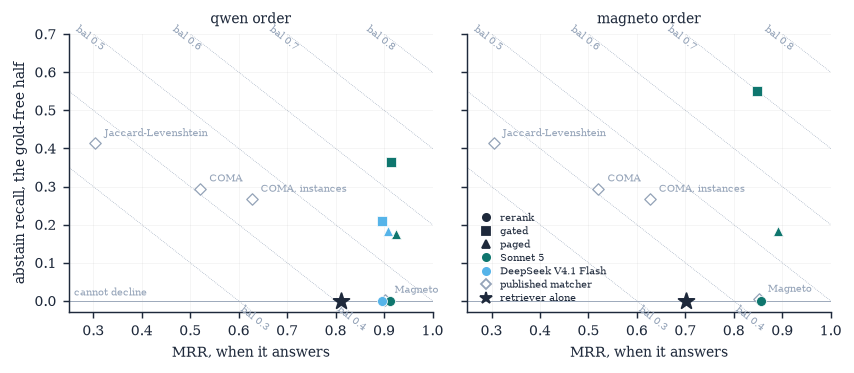

In [13]:
# --- Our arms against the published matchers ------------------------------
# Two axes, because MRR with absence mixes them: `mrr` is the ranking when the
# matcher answers, `abstain_recall` is how much of the gold-free half it
# correctly declined. MRR_bal weights them equally, so its iso-lines have
# slope -1 and the panel reads as one trade-off rather than two numbers.
#
# Faceted by order: a competitor that reads no retrieval order is the same
# point in both panels, our arms and the ceiling are not.
MARK = {"rerank": "o", "gated": "s", "paged": "^"}
COLOUR = {lab: col for lab, col in MODELS.values()}

rows, best_of = [], {}
for ret, F in FULL3.items():
    comp = F[~F["method"].isin(list(MARK) + ["retriever alone"])]
    best = comp.loc[comp["mrr_abstain"].idxmax()] if len(comp) else None
    best_of[ret] = best
    for r in F.to_dict("records"):
        rows.append({
            "order": ret, "method": r["method"], "model": r["model"],
            "calls": r["calls"], "mrr": r["mrr"],
            "abstain_recall": r["abstain_recall"],
            "mrr_abstain": r["mrr_abstain"], "bal": r["bal"],
            "f1_committed": r["f1_committed"],
            "over best competitor": (float("nan") if best is None
                                     else r["mrr_abstain"] - best["mrr_abstain"]),
        })

COMPARE = pd.DataFrame(rows)
COMPARE.to_csv(TABDIR / "table_vs_competitors.csv", index=False)
for ret, g in COMPARE.groupby("order", sort=False):
    b = best_of[ret]
    print("")
    print(f"{ret} order. Best published matcher: "
          f"{b['method']}, MRR with absence {b['mrr_abstain']:.3f}")
    display(g.drop(columns="order").round(3))

fig, axes = plt.subplots(1, len(FULL3), figsize=(3.3 * len(FULL3), 2.9),
                         sharex=True, sharey=True)
axes = np.atleast_1d(axes)
XLO, XHI, YLO, YHI = 0.25, 1.0, -0.03, 0.70

for ax, (ret, F) in zip(axes, FULL3.items()):
    # An arm that cannot decline sits on this line by construction, not by
    # failing: `rerank` has no way to answer NONE, so its abstain recall is 0.
    ax.axhline(0, lw=0.5, color=C_MUTE, zorder=0)
    for b in (0.3, 0.4, 0.5, 0.6, 0.7, 0.8):
        ax.plot([0, 1.3], [2 * b, 2 * b - 1.3], lw=0.4, ls=":",
                color=C_MUTE, zorder=0)
        # Label where the line leaves the axes: the top edge for the high
        # ones, the bottom for the low, so no label crosses a point.
        top, bottom = (2 * b - YHI, YHI), (2 * b, YLO)
        x, y = top if XLO <= top[0] <= XHI else bottom
        if XLO <= x <= XHI:
            ax.annotate(f"bal {b:g}", (x, y), fontsize=5.5, color=C_MUTE,
                        ha="left" if y == YLO else "center",
                        va="bottom" if y == YLO else "top",
                        rotation=-38, rotation_mode="anchor")

    for r in F.to_dict("records"):
        x, y = r["mrr"], r["abstain_recall"]
        if r["method"] == "retriever alone":
            ax.scatter(x, y, marker="*", s=85, color=C_INK, zorder=4)
        elif r["method"] not in MARK:
            ax.scatter(x, y, marker="D", s=20, facecolor="white",
                       edgecolor=C_MUTE, linewidth=0.7, zorder=3)
            label = r["method"].replace("Magneto's protocol", "Magneto")
            ax.annotate(label, (x, y), textcoords="offset points",
                        xytext=(5, 4), fontsize=5.5, ha="left", color=C_MUTE)
        else:
            ax.scatter(x, y, marker=MARK[r["method"]], s=30, zorder=5,
                       color=COLOUR.get(r["model"], C_INK),
                       edgecolor="white", linewidth=0.4)

    ax.set_title(f"{ret} order", fontsize=7.5)
    ax.set_xlabel("MRR, when it answers")
    ax.set_xlim(XLO, XHI)
    ax.set_ylim(YLO, YHI)

axes[0].set_ylabel("abstain recall, the gold-free half")
axes[0].annotate("cannot decline", (XLO + 0.01, 0.008), fontsize=5.5,
                 color=C_MUTE, ha="left", va="bottom")

handles = [plt.Line2D([], [], marker=m, ls="", color=C_INK, ms=4, label=a)
           for a, m in MARK.items()]
handles += [plt.Line2D([], [], marker="o", ls="", color=c, ms=4, label=lab)
            for lab, c in COLOUR.items()]
handles += [plt.Line2D([], [], marker="D", ls="", mfc="white", mec=C_MUTE,
                       color=C_MUTE, ms=4, label="published matcher"),
            plt.Line2D([], [], marker="*", ls="", color=C_INK, ms=7,
                       label="retriever alone")]
axes[-1].legend(handles=handles, fontsize=5.5, loc="lower left",
                frameon=False, handletextpad=0.4, labelspacing=0.3)
fig.tight_layout()
save(fig, "fig5_vs_competitors")
plt.show()


In [14]:
# --- Table 4: MRR with absence and calls per column, under each filter ----
# Pooled exactly as Table 3 is. A filtered run declines the columns the filter
# removed without a call, so its MRR-with-absence and its cost move together.
FILTERS = {"": "none", "mutual": "mutual", "zero": "zero",
           "mutual-zero": "mutual+zero", "zerosrc": "zerosrc", "zerosrc-zero": "zerosrc+zero"}

inv_f = tagged(inventory.scan(RUNS, corpus=CORPUS, pairs=NAMES, kinds=tuple(ARMS)))
inv_f = inv_f[(inv_f["rep"] == 1) & (inv_f["retriever"] == RETRIEVER)
              & inv_f["model"].isin(MODELS) & inv_f["variant"].isin(VARIANTS)
              & inv_f["prune"].isin(FILTERS)
              & ((inv_f["kind"] != "paged") & (inv_f["top_k"] == TOP_K)
                 | (inv_f["kind"] == "paged") & (inv_f["window"] == WINDOW)
                 & (inv_f["threshold"] == TAU))]
OK_F = tagged(inventory.check(inv_f, verbose=False, max_fallback=1.0))

rows = []
for f, flabel in FILTERS.items():
    for arm in ARMS:
        for m in MODELS:
            runs = OK_F[(OK_F["kind"] == arm) & (OK_F["model"] == m)
                        & (OK_F["prune"] == f)]
            if set(runs["pair"]) != set(NAMES) or runs["n_columns"].sum() != N_SRC:
                print(f"not whole: {arm} / {MODELS[m][0]} / {flabel}: "
                      f"{len(set(runs['pair']))} of {len(NAMES)} studies, "
                      f"{int(runs['n_columns'].sum()):,} of {N_SRC}")
                continue
            share = retriever_share(runs)
            if share > MAX_FB:
                print(f"excluded: {arm} / {MODELS[m][0]} / {flabel}: the "
                      f"retriever answered {share:.1%} of the columns")
                continue
            s = report.score(runs, PAIRS, results=RUNS, corpus=CORPUS,
                             kind=arm).iloc[0]
            rows.append({"filter": flabel, "arm": arm, "model": MODELS[m][0],
                         "pruned": int(s["n_pruned"]),
                         "mrr": s["mrr"], "mrr_abstain": s["mrr_abstain"],
                         "f1_committed": s["f1_committed"],
                         "calls/col": s["calls_per_column"],
                         "tokens/col": s["tokens_in_per_column"]})

TABLE4 = pd.DataFrame(rows)
TABLE4.to_csv(TABDIR / "table4_filters.csv", index=False)
display(TABLE4.round(3))

if len(TABLE4):
    print("")
    print("MRR with absence, by filter:")
    display(TABLE4.pivot_table(index=["arm", "model"], columns="filter",
                               values="mrr_abstain").round(3))
    print("calls per column, by filter:")
    display(TABLE4.pivot_table(index=["arm", "model"], columns="filter",
                               values="calls/col").round(2))


not whole: rerank / Sonnet 5 / zerosrc: 0 of 10 studies, 0 of 569


not whole: gated / Sonnet 5 / zerosrc: 0 of 10 studies, 0 of 569


not whole: paged / Sonnet 5 / zerosrc: 0 of 10 studies, 0 of 569


not whole: rerank / Sonnet 5 / zerosrc+zero: 0 of 10 studies, 0 of 569


not whole: gated / Sonnet 5 / zerosrc+zero: 0 of 10 studies, 0 of 569


...

,filter,arm,model,pruned,mrr,mrr_abstain,f1_committed,calls/col,tokens/col
0,none,rerank,Sonnet 5,0,0.913,0.265,0.401,1.00,1367.293
1,none,rerank,DeepSeek V4.1 Flash,0,0.896,0.260,0.390,1.00,967.272
2,none,gated,Sonnet 5,0,0.915,0.524,0.503,1.00,1596.293
3,none,gated,DeepSeek V4.1 Flash,0,0.896,0.409,0.442,1.00,1129.272
4,none,paged,Sonnet 5,0,0.924,0.393,0.449,6.07,9549.564
5,none,paged,DeepSeek V4.1 Flash,0,0.908,0.393,0.436,6.04,6726.605
6,mutual,rerank,Sonnet 5,234,0.845,0.635,0.544,0.59,813.989
7,mutual,rerank,DeepSeek V4.1 Flash,234,0.821,0.628,0.520,0.59,575.605
8,mutual,gated,Sonnet 5,234,0.838,0.733,0.608,0.59,948.814
9,mutual,gated,DeepSeek V4.1 Flash,234,0.818,0.680,0.551,0.59,670.982



MRR with absence, by filter:


filter                      mutual  mutual+zero   none   zero  zerosrc  zerosrc+zero
arm    model                                                                        
gated  DeepSeek V4.1 Flash   0.680        0.702  0.409  0.373    0.501         0.500
       Sonnet 5              0.733        0.740  0.524  0.541      NaN           NaN
paged  DeepSeek V4.1 Flash   0.687        0.707  0.393  0.451    0.515         0.539
       Sonnet 5              0.712        0.742  0.393  0.518      NaN           NaN
rerank DeepSeek V4.1 Flash   0.628        0.628  0.260  0.257    0.402         0.401
       Sonnet 5              0.635        0.633  0.265  0.263      NaN           NaN

calls per column, by filter:


filter                      mutual  mutual+zero  none  zero  zerosrc  zerosrc+zero
arm    model                                                                      
gated  DeepSeek V4.1 Flash    0.59         0.59  1.00  1.00     0.86          0.86
       Sonnet 5               0.59         0.59  1.00  1.00      NaN           NaN
paged  DeepSeek V4.1 Flash    2.86         1.73  6.04  3.82     5.24          2.80
       Sonnet 5               3.47         2.04  6.07  4.51      NaN           NaN
rerank DeepSeek V4.1 Flash    0.59         0.59  1.00  1.00     0.86          0.86
       Sonnet 5               0.59         0.59  1.00  1.00      NaN           NaN

In [15]:
# --- Table 5: what `mutual` removed ---------------------------------------
# Each removed column classified by what the UNFILTERED run did with it. The
# classification reads the labels and an earlier run, so it explains a result
# rather than producing one.
from schemaoracle import pruning
from evaluation.matching import classify_columns

removed, with_gold, pairs_lost = set(), set(), 0
for p in PAIRS:
    name = cache.fs_safe(p["name"])
    raw = json.loads(cache.retrieval_path(RUNS, CORPUS, p["name"], RETRIEVER)
                     .read_text(encoding="utf-8"))["rankings"]
    order = {k: [(t, float(s)) for t, s in v] for k, v in raw.items()}
    gold = {}
    for s, t in p["ground_truth"]:
        gold.setdefault(str(s), set()).add(t)
    for col in pruning.plan(order, "mutual").skip():
        key = report.namespaced(name, col)
        removed.add(key)
        if col in gold:
            with_gold.add(key)
            pairs_lost += len(gold[col])

n_gold_pairs = sum(len(p["ground_truth"]) for p in PAIRS)
print(f"mutual removes {len(removed)} of {N_SRC} source columns "
      f"({len(removed) / N_SRC:.1%})")
print(f"  of those, {len(with_gold)} have a gold target, carrying "
      f"{pairs_lost} of {n_gold_pairs} gold pairs "
      f"({pairs_lost / n_gold_pairs:.1%})")

LABEL = {"TP": "ranked its gold first",
         "FP_FN_wrong": "ranked the wrong target first",
         "FP_invented": "invented an answer (no gold)",
         "FN_abstained": "declined, but had gold",
         "TN_declined": "declined, correctly",
         "no_answer_gold": "no readable answer, had gold",
         "no_answer_free": "no readable answer, no gold"}

rows = []
for arm in ARMS:
    for m in MODELS:
        if (RETRIEVER, arm, m) not in RUNS_OF:
            continue
        rk, gt, com, abst = report.pool(RUNS_OF[RETRIEVER, arm, m].itertuples(),
                                        PAIRS)
        cls = classify_columns(rk, gt, com, abstained=abst)
        counts = {}
        for key in removed:
            if key in cls:
                counts[cls[key]] = counts.get(cls[key], 0) + 1
        rows.append({"arm": arm, "model": MODELS[m][0],
                     **{LABEL[k]: counts.get(k, 0) for k in LABEL}})

TABLE5 = pd.DataFrame(rows)
TABLE5.to_csv(TABDIR / "table5_mutual_removed.csv", index=False)
print("")
print("the removed columns, by what the unfiltered run did with them:")
display(TABLE5)


mutual removes 234 of 569 source columns (41.1%)
  of those, 12 have a gold target, carrying 18 of 259 gold pairs (6.9%)

the removed columns, by what the unfiltered run did with them:


,arm,model,ranked its gold first,ranked the wrong target first,invented an answer (no gold),"declined, but had gold","declined, correctly","no readable answer, had gold","no readable answer, no gold"
0,rerank,Sonnet 5,11,1,222,0,0,0,0
1,rerank,DeepSeek V4.1 Flash,11,1,222,0,0,0,0
2,gated,Sonnet 5,10,2,130,0,92,0,0
3,gated,DeepSeek V4.1 Flash,11,1,177,0,45,0,0
4,paged,Sonnet 5,10,2,181,0,41,0,0
5,paged,DeepSeek V4.1 Flash,11,1,181,0,41,0,0
